In [1]:
pip install engineering_notation

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from engineering_notation import EngNumber
from matplotlib.widgets import Slider, Button
from matplotlib.colors import Normalize
import matplotlib.cm as cm


# Dados do Transformador e do Filtro

In [3]:
V_fund = 34.5e3
f_fund = 60
w_fund = 2*np.pi*f_fund

S_trafo = 60e6
Z_baseTrafo = V_fund**2 / S_trafo
Z_trafo = ( 1.2e-3 + 1j*61e-3) * Z_baseTrafo

h_filtrar = 3
d = 2/100
h_0 = (1-d)*h_filtrar
Q_filtro = 2.8e6
FQual = 80

In [4]:
X_F = V_fund**2 / Q_filtro

$${h_0}\,\omega  = \frac{1}{{\sqrt {L\,C} }} \Rightarrow h_0^2 = \frac{1}{{{\omega ^2}L\,C}} = \frac{1}{{\omega \,C\,\omega L}} = \frac{{{X_C}}}{{{X_L}}}$$

In [5]:
h02 = h_0**2

$$\left. \begin{gathered}
  {X_F} = {X_C} - {X_L} \hfill \\
  h_0^2 = \frac{{{X_C}}}{{{X_L}}} \hfill \\ 
\end{gathered}  \right\} \Rightarrow \left\{ \begin{gathered}
  {X_C} = \frac{1}{{h_0^2 - 1}}{X_F} \hfill \\
  {X_C} = \frac{{h_0^2}}{{h_0^2 - 1}}{X_F} \hfill \\ 
\end{gathered}  \right.$$

In [6]:
X_L =   1/(h02-1) * X_F
L = X_L / w_fund

In [7]:
X_C = h02/(h02-1) * X_F
C = 1 / ( X_C* w_fund )

In [8]:
f_max = ( 1 / np.sqrt(L*C) ) / ( 2 * np.pi )

$$Q_0 = 2\pi \frac{{{W_{{\text{max_armazenada}}}}}}{{{W_{{\text{perdida}}}}}}=2\pi \frac{{\frac{{L{I^2}}}{2}}}{{R{I^2}\frac{{2\pi }}{f}}} = \frac{{\omega L}}{R} = \frac{1}{{\omega CR}} = \frac{{\sqrt {\frac{L}{C}} }}{R}$$

In [9]:
Z0 = np.sqrt(L/C)
R  = Z0 / FQual

In [10]:
Z_RL = R + 1j*X_L
Y_RL = 1 / Z_RL
R_paralelo = 1 / np.real(Y_RL)
X_L_paralelo = - 1 / np.imag(Y_RL)
L_paralelo = X_L_paralelo / w_fund

In [11]:
f = np.arange(60, 600.1, 0.1)
w = 2*np.pi*f
Zfiltro = R + 1j*w*L + 1/(1j*w*C)
Zmod = np.abs(Zfiltro)
Zang = np.angle(Zfiltro, deg=True)

## Filtro

In [12]:
Ifiltro = ( V_fund/np.sqrt(3) ) / Zfiltro[0]
Vindutor   =  1j * X_L * Ifiltro
Vcapacitor = -1j * X_C * Ifiltro
Vresistor  =         R * Ifiltro 
# conf = np.sqrt(3) * (Vresistor+Vcapacitor+Vindutor)
# conf

In [13]:
I_Rparalelo = ( Vindutor + Vresistor ) / R_paralelo
I_Lparalelo = ( Vindutor + Vresistor ) / (1j*X_L_paralelo)
I_Cserie = I_Rparalelo + I_Lparalelo
V_Cserie = 1/(1j*w_fund*C)  * I_Cserie
# conf = np.sqrt(3) * (V_Cserie+I_Lparalelo*1j*X_L_paralelo)
# conf

In [14]:
Qcap = 3*Vcapacitor * np.conj(Ifiltro)
Qind = 3*Vindutor   * np.conj(Ifiltro)
Qfil = np.imag( Qcap - Qind )
Pfil = 3*R*np.abs(Ifiltro)**2

## Transformador

In [15]:
X_trafo = np.imag(Z_trafo)/w_fund * w
R_trafo = np.real(Z_trafo) * w/w
Z_trafoFreq = R_trafo + 1j*X_trafo

## Filtro em paralelo com o transformador

In [16]:
Y_filtro = 1 / Zfiltro
Y_trafo  = 1 / Z_trafoFreq
Y_trafoFiltro = Y_filtro + Y_trafo
Z_trafoFiltro = 1 / Y_trafoFiltro

## Saídas

In [17]:
print('=== No circuito RLC série===')
print('   R    = ', EngNumber(R))
print('   L    = ', EngNumber(L))
print('   C    = ', EngNumber(C))
print('   Vcap = ', EngNumber(np.abs(Vcapacitor)), '\u2221', EngNumber(np.angle(Vcapacitor, deg=True)))
print('   Vind = ', EngNumber(np.abs(Vindutor)), '\u2221', EngNumber(np.angle(Vindutor, deg=True)))
print('   Iser = ', EngNumber(np.abs(Ifiltro)), '\u2221', EngNumber(np.angle(Ifiltro, deg=True)))
print('   Sfil = ', EngNumber(Pfil), '+ \u2149', EngNumber(Qfil))
print('============================')

=== No circuito RLC série===
   R    =  2.04
   L    =  147.52m
   C    =  5.52u
   Vcap =  22.52k ∡ -275.47m
   Vind =  2.61k ∡ 179.72
   Iser =  46.86 ∡ 89.72
   Sfil =  13.46k + ⅉ -3.53M


In [18]:
print('=== No circuito R//L+C série===')
print('   Rpar         = ', EngNumber(R_paralelo))
print('   Lpar         = ', EngNumber(L_paralelo))
print('   Cser         = ', EngNumber(C))
print('   V_Cserie     = ', EngNumber(np.abs(V_Cserie)), '\u2221', EngNumber(np.angle(V_Cserie, deg=True)))
print('   I_Cserie     = ', EngNumber(np.abs(I_Cserie)), '\u2221', EngNumber(np.angle(I_Cserie, deg=True)))
print('   Vindparalelo = ', EngNumber(np.abs(Vindutor)), '\u2221', EngNumber(np.angle(Vindutor, deg=True)))
print('   Iindparalelo = ', EngNumber(np.abs(I_Lparalelo)), '\u2221', EngNumber(np.angle(I_Lparalelo, deg=True)))
print('   Iresparalelo = ', EngNumber(np.abs(I_Rparalelo)), '\u2221', EngNumber(np.angle(I_Rparalelo, deg=True)))

=== No circuito R//L+C série===
   Rpar         =  1.52k
   Lpar         =  147.72m
   Cser         =  5.52u
   V_Cserie     =  22.52k ∡ -275.47m
   I_Cserie     =  46.86 ∡ 89.72
   Vindparalelo =  2.61k ∡ 179.72
   Iindparalelo =  46.83 ∡ 87.62
   Iresparalelo =  1.72 ∡ 177.62


## Largura de faixa

In [19]:
w0 = 1 / np.sqrt(L*C)
Q0 = w0*L/R
BW = w0 / Q0
w1 = w0 - BW/2
w2 = w0 + BW/2
print('Largura de faixa             = ', EngNumber(BW/(2*np.pi)), 'Hz')
print('Fator de qualidade           = ', EngNumber(Q0) )
print('Frequência de ressonância    = ', EngNumber(w0/(2*np.pi)), 'Hz')
print('Frequências de meia potência = ', EngNumber(w1/(2*np.pi)), 'Hz e ', EngNumber(w2/(2*np.pi)), 'Hz')

Largura de faixa             =  2.20 Hz
Fator de qualidade           =  80
Frequência de ressonância    =  176.40 Hz
Frequências de meia potência =  175.30 Hz e  177.50 Hz


## Gráficos

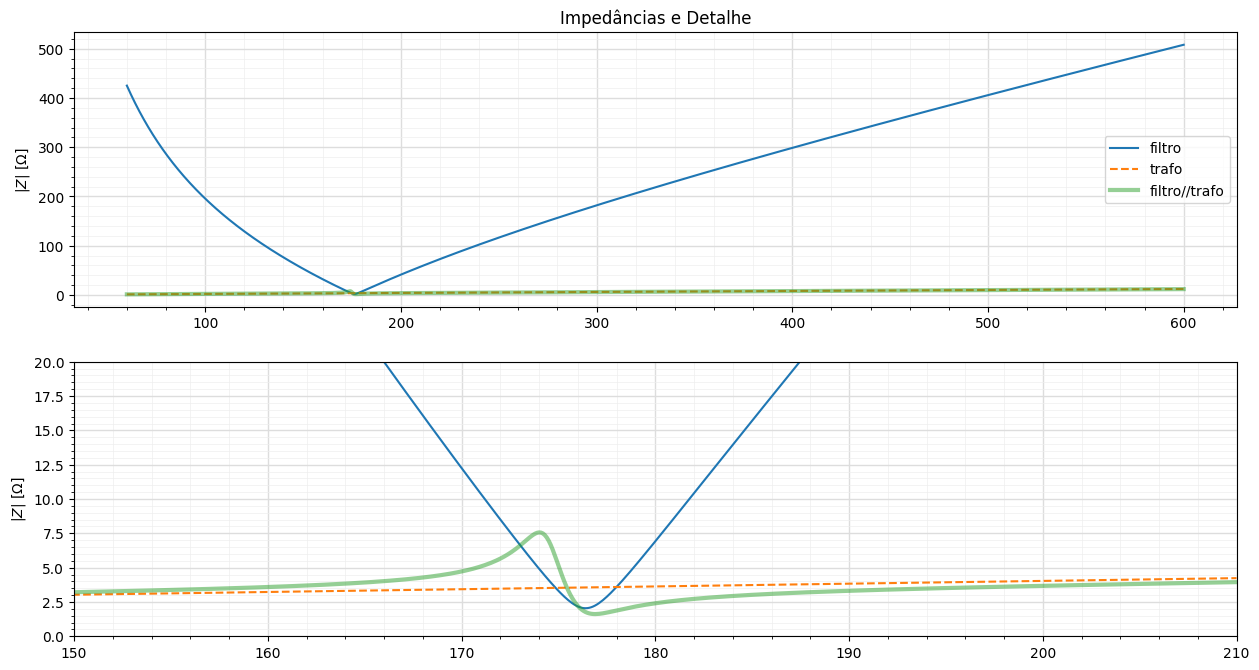

In [20]:
fig, axs = plt.subplots(2, 1)
fig.dpi = 100
fig.set_size_inches(15, 8)
axs[0].plot(f, Zmod, label='filtro')
axs[0].plot(f, np.abs(Z_trafoFreq), label='trafo', ls='--')
axs[0].plot(f, np.abs(Z_trafoFiltro), label='filtro//trafo', lw=3, alpha=0.5)
axs[0].grid(which='major', color='#DDDDDD', linewidth=1.0)
axs[0].minorticks_on()
axs[0].grid(which='minor', color='#EEEEEE', linewidth=0.5)
axs[0].set_ylabel('$|Z|$ [$\Omega$]')
axs[0].set_title('Impedâncias e Detalhe')
axs[0].legend()

axs[1].plot(f, Zmod, label='filtro')
axs[1].plot(f, np.abs(Z_trafoFreq), label='trafo', ls='--')
axs[1].plot(f, np.abs(Z_trafoFiltro), label='tudo', lw=3, alpha=0.5)
axs[1].grid(which='major', color='#DDDDDD', linewidth=1.0)
axs[1].minorticks_on()
axs[1].grid(which='minor', color='#EEEEEE', linewidth=0.5)
axs[1].set_ylim(0, 20)
axs[1].set_xlim(f_fund*(h_filtrar-1/2), f_fund*(h_filtrar+1/2))
axs[1].set_ylabel('$|Z|$ [$\Omega$]')

plt.show()